<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_32_Patching_Hidden_states_in_Indirect_object_identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from scipy.optimize import curve_fit

from tqdm import tqdm

from transformers import GPT2LMHeadModel, GPT2Tokenizer
import torch

# Part_1:The IOI Task

## Task_1:
- Import GPT-2-xl and move it to the GPU. Tokenize the following
two sentences (excluding the numbers):
1. When Mike and Emma went to the cafe, Mike gave a
coffee to
2. When Mike and Emma went to the cafe, Emma gave a
coffee to
Find the token indices for “ Mike” and “ Emma” (including the
preceding spaces).
Push both token sequences through the model and output the
hidden states. You can do one forward pass with batched input,
although I found it more convenient for subsequent analyses to have
two separate runs with separate output variable names

In [2]:

device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = GPT2LMHeadModel.from_pretrained('gpt2-xl').to(device)
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

n_layers = model.config.n_layer
model.eval()

config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 6.43GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1600)
    (wpe): Embedding(1024, 1600)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-47): 48 x GPT2Block(
        (ln_1): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=4800, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=1600)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=6400, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=6400)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=1600, out_features=50257, bias=False)
)

In [3]:
n_layers

48

In [4]:

text_ME = 'When Mike and Emma went to the cafe, Mike gave a coffee to'
text_EM = 'When Mike and Emma went to the cafe, Emma gave a coffee to'

target_M = tokenizer.encode(' Mike')[0]
target_E = tokenizer.encode(' Emma')[0]

tokensME = tokenizer.encode(text_ME,return_tensors='pt').to(device)
tokensEM = tokenizer.encode(text_EM,return_tensors='pt').to(device)


In [5]:
target_M

4995

In [6]:
tokensEM

tensor([[ 2215,  4995,   290, 18966,  1816,   284,   262, 26725,    11, 18966,
          2921,   257,  6891,   284]], device='cuda:0')

In [7]:

with torch.no_grad():
  outME = model(tokensME,output_hidden_states=True)
  outEM = model(tokensEM,output_hidden_states=True)

hs_ME = outME.hidden_states
outME.keys(), outME.hidden_states[3].shape

(odict_keys(['logits', 'past_key_values', 'hidden_states']),
 torch.Size([1, 14, 1600]))

In [8]:
len(hs_ME)

49

In [9]:
outEM.keys()

odict_keys(['logits', 'past_key_values', 'hidden_states'])

## Task_2:
- Determine whether GPT-2-xl solves the IOI task by identifying the
token with the largest logit in the final token position. Print out
both sentences with the newly generated ending.
Make a scatter plot of the raw logits in the final token posi
tion for both sentences, and highlight the vocab indices for “ Mike”
and “ Emma” as in Figure 5.51A-B. Show a scatter plot of the logits
for the final token from the two sentences as in Figure 5.51C.
Calculate the IOI score as the raw logit values for “ Mike”
minus “ Emma” in both sentences. These IOI scores will be a clean
baseline for the results of the patching experiment later in the
project

In [14]:

# predicted next words
nextword_ME = torch.argmax(outME.logits[0,-1,:])
nextword_EM = torch.argmax(outEM.logits[0,-1,:])

print(f'{text_ME}"{tokenizer.decode(nextword_ME)}"')
print(f'{text_EM}"{tokenizer.decode(nextword_EM)}"')


When Mike and Emma went to the cafe, Mike gave a coffee to" Emma"
When Mike and Emma went to the cafe, Emma gave a coffee to" Mike"


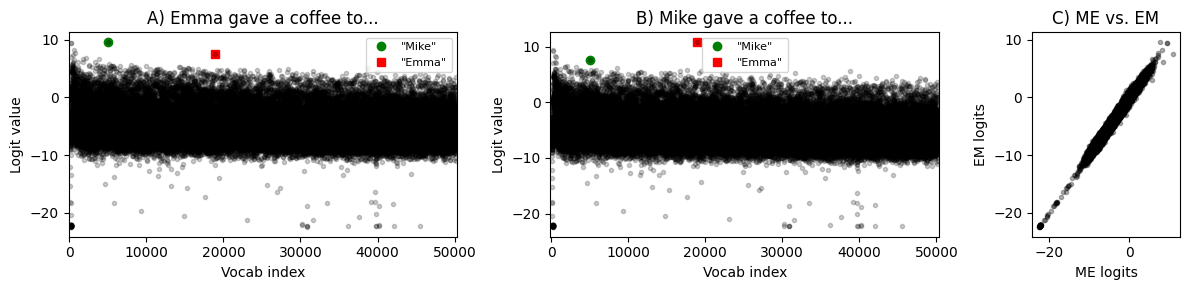

In [15]:
logits_ME = outME.logits[0,-1,:].detach().cpu()
logits_EM = outEM.logits[0,-1,:].detach().cpu()


# setup the figure
fig = plt.figure(figsize=(12,3))
gs = GridSpec(1,5,figure=fig)
ax1 = fig.add_subplot(gs[:2])
ax2 = fig.add_subplot(gs[2:4])
ax3 = fig.add_subplot(gs[-1])

# plot log-sm from "EM" sentence
ax1.plot(target_M,logits_EM[target_M],'go',label='"Mike"')
ax1.plot(target_E,logits_EM[target_E],'rs',label='"Emma"')
ax1.plot(logits_EM,'k.',alpha=.2)
ax1.legend(fontsize=8)
ax1.set(xlabel='Vocab index',ylabel='Logit value',
           title='A) '+text_EM[-21:]+'...',xlim=[-100,tokenizer.vocab_size+100])

# plot log-sm from "ME" sentence
ax2.plot(target_M,logits_ME[target_M],'go',label='"Mike"')
ax2.plot(target_E,logits_ME[target_E],'rs',label='"Emma"')
ax2.plot(logits_ME,'k.',alpha=.2)
ax2.legend(fontsize=8)
ax2.set(xlabel='Vocab index',ylabel='Logit value',
           xlim=[-100,tokenizer.vocab_size+100],title='B) '+text_ME[-21:]+'...')

# how they relate to each other
ax3.plot(logits_ME,logits_EM,'k.',alpha=.3)
ax3.set(xlabel='ME logits',ylabel='EM logits',title='C) ME vs. EM')

plt.tight_layout()
plt.show()



In [18]:
outME.logits[0,-1,target_M]

tensor(7.6097, device='cuda:0')

In [16]:

IOI_score_ME = outME.logits[0,-1,target_M] - outME.logits[0,-1,target_E]
IOI_score_EM = outEM.logits[0,-1,target_M] - outEM.logits[0,-1,target_E]

print(f'IOI score for text "ME": {IOI_score_ME:6.3f}')
print(f'IOI score for text "EM": {IOI_score_EM:6.3f}')

IOI score for text "ME": -3.313
IOI score for text "EM":  2.177


# Part 2: IOI with hidden-state patching

## Task_1:
- Choose layer L − 2 (L layers) to patch. Write a hook function
that replaces the transformer outputs from the final token with
the corresponding activations from the ME hidden states that you
extracted from the model output in Part 1.
Attach that hook to transformer layer L − 2. Run the EM to
kens through the model. Remove the hook function.
Calculate and report the IOI scores from the patched and clean
models.
Calculate and show the logits from the clean and patched models
as in Figure 5.52A-B, and their token-wise differences, as in Figure
5.52C. In all plots, highlight the two target tokens

In [20]:


# pick one layer
layeri = model.config.n_layer-2

# patch this layer
def hookfun(module, input, output):
  hs = output.clone() # make a copy
  hs[0,-1,:] = outME.hidden_states[layeri+1][0,-1,:] # index +1!
  return hs

# implant the hook
handle = model.transformer.h[layeri].register_forward_hook(hookfun)

# forward pass with hook
with torch.no_grad():
  outEM_patch = model(tokensEM,output_hidden_states=True)

# remove the hook
handle.remove()

# now for the IOI score test
IOI_score = outEM_patch.logits[0,-1,target_M] - outEM_patch.logits[0,-1,target_E]

In [21]:
IOI_score

tensor(-3.3160, device='cuda:0')

In [22]:

print(f'  Clean IOI score: {IOI_score_EM:6.3f}')
print(f'Patched IOI score: {IOI_score:6.3f}')

  Clean IOI score:  2.177
Patched IOI score: -3.316


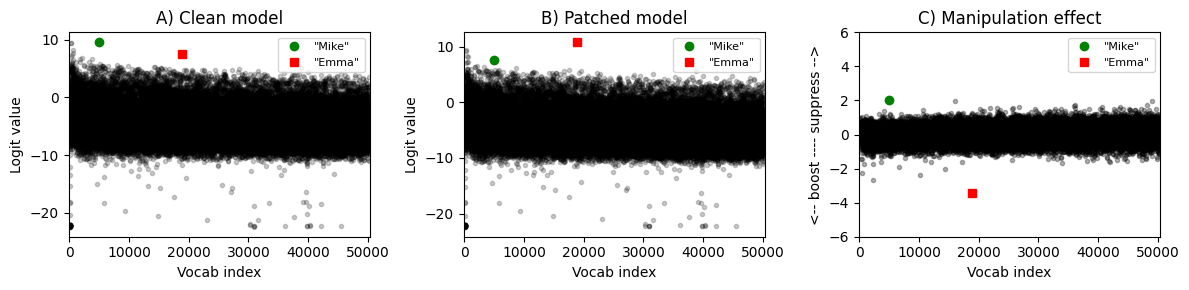

In [23]:

logits_EM_patch = outEM_patch.logits[0,-1,:].detach().cpu()

# setup the figure
fig,axs = plt.subplots(1,3,figsize=(12,3))

# plot log-sm from "EM" sentence from the clean model
axs[0].plot(logits_EM,'k.',alpha=.2)
axs[0].plot(target_M,logits_EM[target_M],'go',label='"Mike"')
axs[0].plot(target_E,logits_EM[target_E],'rs',label='"Emma"')
axs[0].legend(fontsize=8)
axs[0].set(xlabel='Vocab index',ylabel='Logit value',
           title='A) Clean model',xlim=[-100,tokenizer.vocab_size+100])

# plot log-sm from "EM" sentence from the patched model
axs[1].plot(logits_EM_patch,'k.',alpha=.2)
axs[1].plot(target_M,logits_EM_patch[target_M],'go',label='"Mike"')
axs[1].plot(target_E,logits_EM_patch[target_E],'rs',label='"Emma"')
axs[1].legend(fontsize=8)
axs[1].set(xlabel='Vocab index',ylabel='Logit value',
           title='B) Patched model',xlim=[-100,tokenizer.vocab_size+100])

# impact of patching on all token probs
logits_diff = logits_EM - logits_EM_patch
axs[2].plot(logits_diff,'k.',alpha=.3)
axs[2].plot(target_M,logits_diff[target_M],'go',label='"Mike"')
axs[2].plot(target_E,logits_diff[target_E],'rs',label='"Emma"')
axs[2].legend(fontsize=8)
axs[2].set(xlabel='Vocab index',ylabel='<-- boost ---- suppress -->',ylim=[-6,6],
           title='C) Manipulation effect',xlim=[-100,tokenizer.vocab_size+100])

plt.tight_layout()
plt.show()

## Task_2:
- Find and print out the top-20 impacted tokens. Print the manipula
tion impact (∆ = clean minus patched logits) and the token string.

In [24]:

bigFX = torch.topk(abs(logits_diff),20)
for t in bigFX[1]:
  print(f'Δ (C-P) = {logits_diff[t]:6.3f} for "{tokenizer.decode(t)}"')

Δ (C-P) = -3.437 for " Emma"
Δ (C-P) = -2.681 for " himself"
Δ (C-P) = -2.400 for "Em"
Δ (C-P) = -2.278 for " his"
Δ (C-P) =  2.056 for " Mike"
Δ (C-P) = -2.019 for "his"
Δ (C-P) =  1.997 for " Miko"
Δ (C-P) =  1.981 for "Mike"
Δ (C-P) = -1.905 for "His"
Δ (C-P) = -1.743 for " em"
Δ (C-P) = -1.741 for " Em"
Δ (C-P) =  1.728 for " Pegasus"
Δ (C-P) =  1.719 for " Scor"
Δ (C-P) = -1.697 for "hess"
Δ (C-P) =  1.653 for " Mew"
Δ (C-P) =  1.645 for " Makoto"
Δ (C-P) = -1.641 for " EM"
Δ (C-P) = -1.635 for " wife"
Δ (C-P) = -1.615 for " erection"
Δ (C-P) =  1.599 for "IRO"


In [25]:
nextword= torch.argmax(outEM_patch.logits[0,-1,:])
print(f'{text_EM}"{tokenizer.decode(nextword)}"')


When Mike and Emma went to the cafe, Emma gave a coffee to" Emma"


# Part_1:IOI experiment over layers

## Task_1:
- Loop over all transformer layers. Inside the for-loop, create a hook
function only for that layer to patch in ME hidden-state vectors as
in Part 2. Run a forward pass on the model using the EM tokens.
Calculate and store the IOI score.
Here is the manipulation check: Calculate the norm of the vector
defined by the difference between the patched and the clean hidden
state activations for the current layer. Do this for the penultimate
token position, and for the final token position. The hook function
only patched the final token position, so the penultimate hidden-state
vector should differ (meaning non-zero norms), whereas the final
vector should match perfectly (meaning the difference vector norm
should be zero).
Spoiler: The manipulation check will fail for the final layer.
Understand why it failed and how you could fix it — but don’t
correct it in the code (the incorrect result will be used later).
Visualize the laminar profile of the patched IOI scores, along
with the clean IOI scores, as in Figure 5.53

In [26]:
# initializations
confirmManipulation = np.zeros((n_layers,2))
IOI_scores = np.zeros(n_layers)

# loop over layers
for layeri in tqdm(range(n_layers)):

  # patch this layer
  def hookfun(module,input,output):
    hs = output.clone()
    hs[0,-1,:] = outME.hidden_states[layeri+1][0,-1,:]
    return hs

  # implant the hook
  handle = model.transformer.h[layeri].register_forward_hook(hookfun)

  # forward pass with hook
  with torch.no_grad():
    outEM = model(tokensEM,output_hidden_states=True)
  hs_EM = outEM.hidden_states

  # remove the hook
  handle.remove()

  # confirmation: first element should be zero, second non-zero
  confirmManipulation[layeri,0] = torch.norm( hs_EM[layeri+1][0,-2,:]-hs_ME[layeri+1][0,-2,:] )
  confirmManipulation[layeri,1] = torch.norm( hs_EM[layeri+1][0,-1,:]-hs_ME[layeri+1][0,-1,:] )

  # now for the IOI score
  IOI_scores[layeri] = outEM.logits[0,-1,target_M] - outEM.logits[0,-1,target_E]

100%|██████████| 48/48 [00:02<00:00, 18.35it/s]


In [27]:

# sanity check :)
confirmManipulation

array([[  3.89694047,   2.03984427],
       [  4.65067434,   2.25599456],
       [  5.18620586,   2.25558972],
       [  5.58070612,   2.36141062],
       [  5.68973303,   2.31119084],
       [  5.93348789,   2.33906722],
       [  6.06921196,   2.48799229],
       [  6.29723692,   2.94330144],
       [  6.35259485,   2.99105334],
       [  6.48591185,   3.31091952],
       [  6.42287874,   3.27428174],
       [  6.36038685,   3.39081717],
       [  6.45454788,   3.5955112 ],
       [  6.78931236,   4.70945311],
       [  7.00008106,   5.90908718],
       [  7.6126914 ,   6.60946608],
       [  8.37650204,   8.52767849],
       [  8.678792  ,   8.86404037],
       [ 10.52288818,  12.33177567],
       [ 11.48959351,  14.37230396],
       [ 12.29322147,  15.32363415],
       [ 13.48204899,  21.89552879],
       [ 14.06747246,  34.55329132],
       [ 14.68526077,  39.30944443],
       [ 15.20936775,  42.17374039],
       [ 15.58930206,  45.19909668],
       [ 16.23065376,  59.37772751],
 

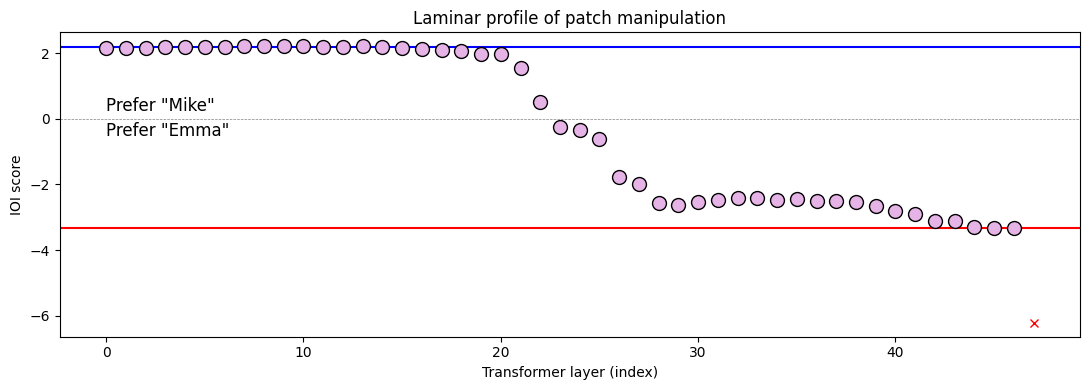

In [28]:

# visualization
plt.figure(figsize=(11,4))

# plot the logit differences for the "clean" runs (no patching)
plt.axhline(IOI_score_EM.cpu(),color='b',label='Clean "EM"')
plt.axhline(IOI_score_ME.cpu(),color='r',label='Clean "ME"')

# then for the experiment results
plt.plot(IOI_scores[:-1],'ko',markerfacecolor=[.9,.7,.9],markersize=10)
plt.plot(n_layers-1,IOI_scores[-1],'rx')

# the dividing line
plt.axhline(0,linestyle='--',color='gray',linewidth=.5)
plt.text(0,.1,'Prefer "Mike"',fontsize=12,va='bottom')
plt.text(0,-.1,'Prefer "Emma"',fontsize=12,va='top')

plt.gca().set(xlabel='Transformer layer (index)',ylabel='IOI score',title='Laminar profile of patch manipulation')

plt.tight_layout()
plt.show()

# Part_4:Curve fitting with scipy

## Task_1:
- Write a Python function, called sigmoid_fun, that takes five input
arguments, corresponding to the five terms in Equation 5.9, in this
order: x,A,x0,k,b. The function implements Equation 5.9 and
returns the values of ˆy.
Test the function by generating 50 linearly spaced numbers be
tween-10 and 10. Then define y using the sigmoid function with
parameters A = 10, x0 = 0, k = 1, b = 2. Then add some random
noise and visualize as in Figure 5.54

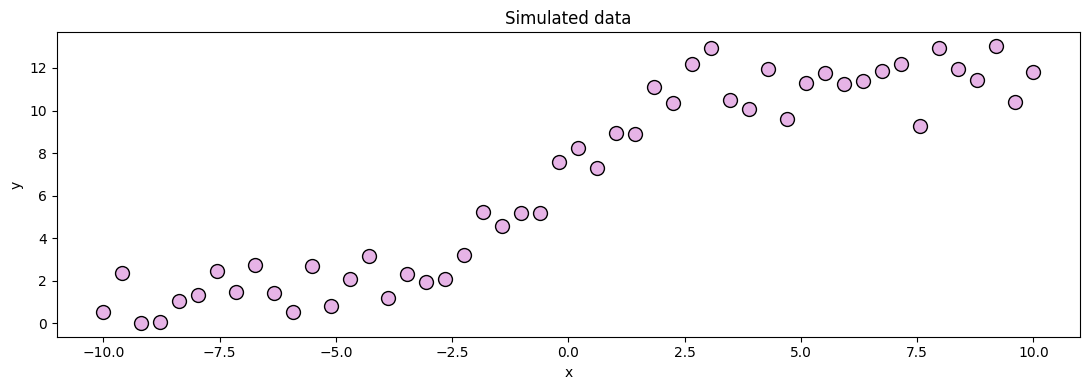

In [29]:

# sigmoid function
def sigmoid_fun(x,A,x0,k,b):
  # params:
  #   A: maximum value
  #  x0: x-value of midpoint
  #   k: curve steepness
  #   b: minimum value
  return A / (1+np.exp(-k * (x-x0))) + b

# create some data
x = np.linspace(-10,10,50)
y = sigmoid_fun(x,10,0,1,2)
y += np.random.randn(len(x))

# visualize them
plt.figure(figsize=(11,4))
plt.plot(x,y,'ko',markerfacecolor=[.9,.7,.9],markersize=10)
plt.gca().set(xlabel='x',ylabel='y',title='Simulated data')

plt.tight_layout()
plt.show()

## Task_2:
- Estimate initial parameters for the search as follows: A is the
maximum value of y; x0 is the median of x; k = 1; b is the minimum
value of y.
Call the curve_fit function with the following input argu
ments: the sigmoid function you wrote earlier, the x-values, the
y-values, and the initial parameter estimates. The first output is an
array of parameter estimates in the same order as they are listed in
the sigmoid function, and the second output is the covariance of the
parameter estimates (not used here).
Print a table of the ground-truth and model-estimated param
eters

In [30]:

# initial parameter guesses [A, x0, k, b]
p0 = [max(y), np.median(x), 1, min(y)]

# fit the sigmoid function to data
est_params,pcov = curve_fit(sigmoid_fun,x,y,p0)

print('    Truth | Estim.')
print('---+------+--------')
print(f' A |  10  | {est_params[0]:5.2f}')
print(f'x0 |   0  | {est_params[1]:5.2f}')
print(f' k |   1  | {est_params[2]:5.2f}')
print(f' b |   2  | {est_params[3]:5.2f}')

    Truth | Estim.
---+------+--------
 A |  10  | 10.26
x0 |   0  | -0.43
 k |   1  |  0.80
 b |   2  |  1.33


## Task_3:
- Plot the data again, this time adding the model-fitted curve. To
generate the model predictions, call the sigmoid function again with
the same values of x but the model-estimated parameters instead of
the ground-truth parameters. Plot the data, the model predictions,
and a vertical line at x0, as in Figure 5.55

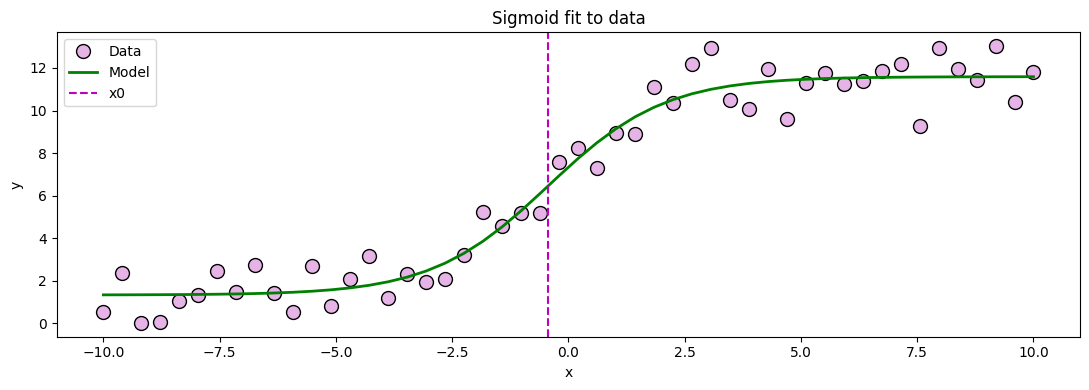

In [31]:
# high-res model predictions
yHat = sigmoid_fun(x,*est_params)

# visualization
plt.figure(figsize=(11,4))

plt.plot(x,y,'ko',markerfacecolor=[.9,.7,.9],markersize=10,label='Data')
plt.plot(x,yHat,'g',linewidth=2,label='Model')
plt.axvline(x=est_params[1],color='m',linestyle='--',label='x0')

plt.legend()
plt.gca().set(xlabel='x',ylabel='y',title=f'Sigmoid fit to data')

plt.tight_layout()
plt.show()

# Part_5:Curve fitting IOI scores


## Task_1:
- Remove the final data point from the vector of IOI scores.
Copy and adapt the code from Part 4 to model the IOI scores. The
x values are the transformer layer indices, and the y values are the
IOI scores.
Visualize the results as in Figure 5.56

In [32]:
IOI_scores = IOI_scores[:n_layers-1]

In [33]:

### now for the real data
x = np.arange(n_layers-1)

# initial parameter guess
p0 = [max(IOI_scores), np.median(x), 1, min(IOI_scores)]

# fit function to data
est_params,pcov = curve_fit(sigmoid_fun,x,IOI_scores,p0)

# high-res model predictions
yHat = sigmoid_fun(x,*est_params)

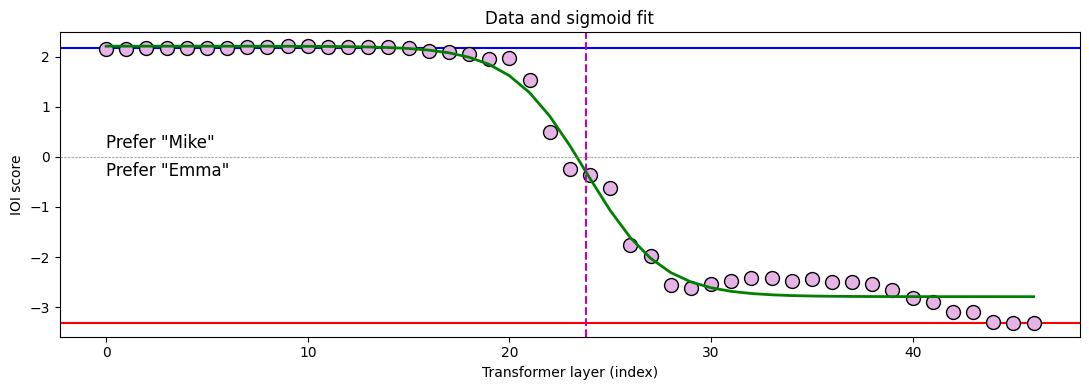

In [34]:

# visualization
plt.figure(figsize=(11,4))

# plot the logit differences for the "clean" runs (no patching)
plt.axhline(IOI_score_EM.cpu(),color='b',label='Clean "EM"')
plt.axhline(IOI_score_ME.cpu(),color='r',label='Clean "ME"')

# then for the experiment results
plt.plot(IOI_scores,'ko',markerfacecolor=[.9,.7,.9],markersize=10,label='Experiment results')

plt.plot(x,yHat,'g',linewidth=2,label='Model')
plt.axvline(x=est_params[1],color='m',linestyle='--',label=f'x0 (L{est_params[1]})')

# the dividing line
plt.axhline(0,linestyle='--',color='gray',linewidth=.5)
plt.text(0,.1,'Prefer "Mike"',fontsize=12,va='bottom')
plt.text(0,-.1,'Prefer "Emma"',fontsize=12,va='top')

plt.gca().set(xlabel='Transformer layer (index)',ylabel='IOI score',title=f'Data and sigmoid fit')

plt.tight_layout()
plt.show()